# Lab 3 - Clustering in Image Color Compression
## JS07 - Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objectives
1. Understand vector quantization and image color compression using clustering techniques.
2. Represent image pixels as coordinates in a 3-dimensional RGB color space.
3. Apply `MiniBatchKMeans` to drastically reduce color space complexity (from 16 million potential colors down to 16 discrete colors).
4. Visualize color distribution before and after clustering in 2D projections.
5. Reconstruct the quantized image and evaluate compression efficiency, visual fidelity, and trade-offs across different cluster sizes ($K$).


## Step 0 - Import Libraries
Import the required modules for numerical computing, visualization, and image data loading.


In [1]:
# Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Set aesthetic styling
sns.set_theme(style='white')
%matplotlib inline


## Step 1 - Load Image Data
Load the standard sample image `flower.jpg` provided by `sklearn.datasets`.


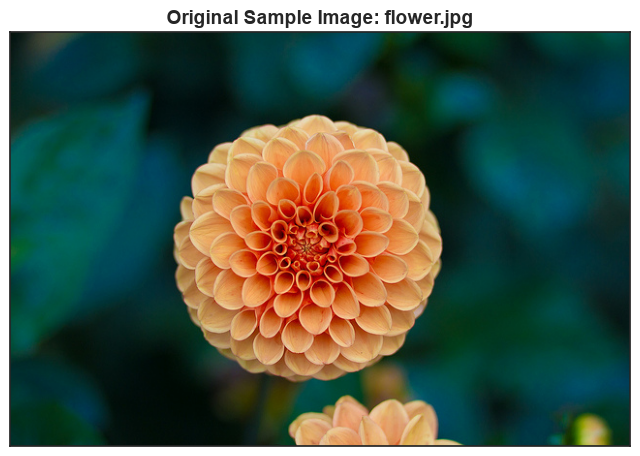

In [2]:
from sklearn.datasets import load_sample_image

# Load sample image
flower = load_sample_image("flower.jpg")

# Display the image
plt.figure(figsize=(8, 6))
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)
plt.title("Original Sample Image: flower.jpg", fontsize=14, fontweight='bold')
plt.show()


## Step 2 - Image Preprocessing
Inspect image dimensions and normalize pixel intensities:
1. Standard 24-bit true color images encode RGB intensities as 8-bit integers from $0$ to $255$.
2. We divide by $255.0$ to scale intensities to the range $[0.0, 1.0]$.
3. Flatten the $3\\text{D}$ array $(\\text{height} \\times \\text{width} \\times 3)$ into a $2\\text{D}$ array $(N \\times 3)$, where each row represents one pixel's RGB coordinates.


In [3]:
# Check shape of the image
print(f"Original image shape: {flower.shape}")
print(f"Total number of pixels: {flower.shape[0] * flower.shape[1]:,}")
print(f"Pixel value range: min={flower.min()}, max={flower.max()}")

# Normalize color values to [0, 1]
data = flower / 255.0

# Reshape into a 2D array of (N_pixels, 3)
data = data.reshape(427 * 640, 3)

print(f"Reshaped data matrix: {data.shape}")


Original image shape: (427, 640, 3)
Total number of pixels: 273,280
Pixel value range: min=0, max=255
Reshaped data matrix: (273280, 3)


## Step 3 - Examine Color Distribution
To understand the initial color variety, we define `plot_pixels()` to draw 2D scatter plots of pixel colors across:
- **Red vs Green**
- **Red vs Blue**

We randomly sample $N = 10,000$ pixels for responsive visualization.


In [4]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data
    
    # Choose a random subset of pixels
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    
    # Red vs Green projection
    ax[0].scatter(R, G, color=colors, marker='.', s=20, alpha=0.6)
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))
    ax[0].set_title('Red vs Green', fontsize=12, fontweight='bold')
    
    # Red vs Blue projection
    ax[1].scatter(R, B, color=colors, marker='.', s=20, alpha=0.6)
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))
    ax[1].set_title('Red vs Blue', fontsize=12, fontweight='bold')

    fig.suptitle(title, size=16, fontweight='bold')
    plt.tight_layout()
    plt.show()


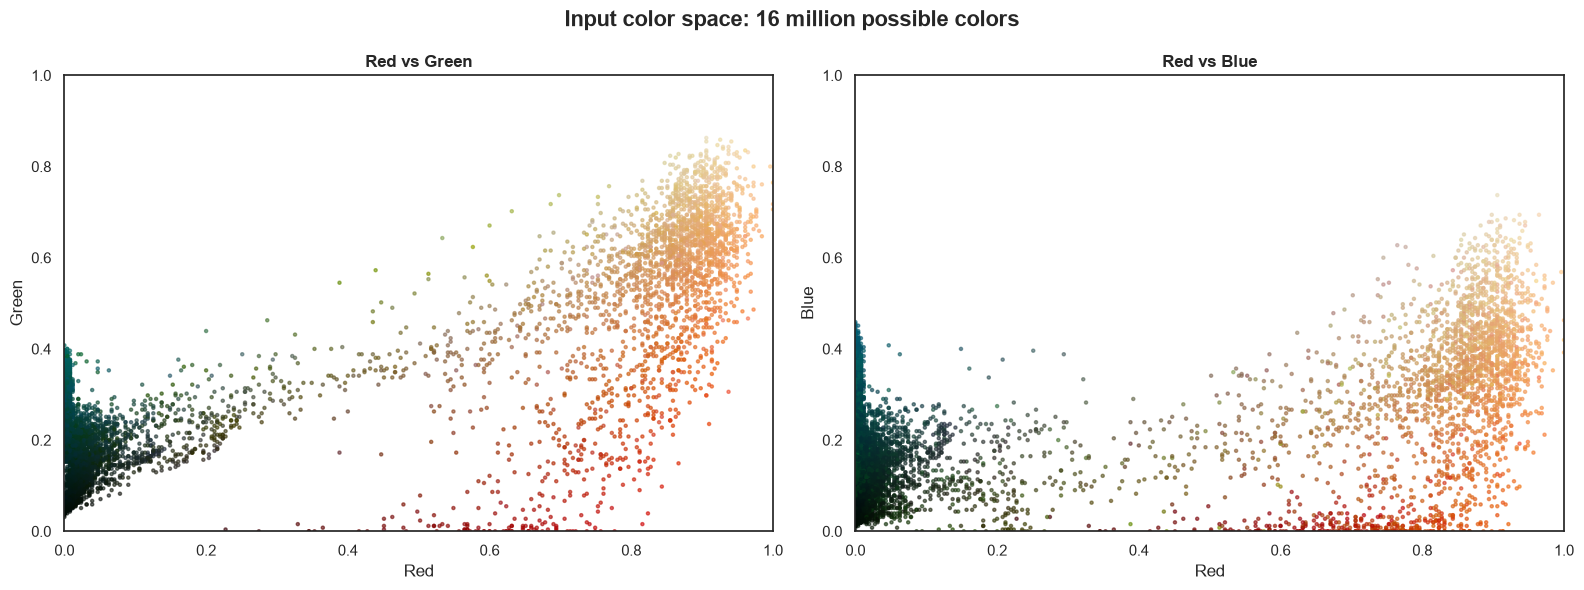

In [5]:
# Visualize original color distribution
plot_pixels(data, title='Input color space: 16 million possible colors')


**Color Space Analysis:**  
The scatter plots reveal a dense, continuous cloud of color values spanning various shades of red, green, and blue. In standard 24-bit color depth, up to $256^3 = 16,777,216$ distinct colors are possible.


## Step 4 - Color Clustering using MiniBatchKMeans ($K = 16$)
We apply `MiniBatchKMeans` with $K = 16$ clusters:
- **Why MiniBatchKMeans?** Standard K-Means computes distances across all $273,280$ pixels on every iteration, which is computationally demanding. `MiniBatchKMeans` draws small random sub-samples (mini-batches) to iteratively update cluster centers, drastically reducing execution time while maintaining virtually identical centroid quality.
- Each pixel is assigned to its nearest cluster centroid, effectively mapping the entire image to just $16$ representative colors.


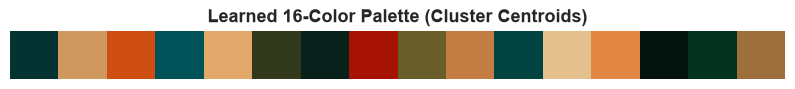

In [6]:
from sklearn.cluster import MiniBatchKMeans

# Construct and fit MiniBatchKMeans
kmeans = MiniBatchKMeans(n_clusters=16, random_state=42, batch_size=1024, n_init=10)
kmeans.fit(data)

# Map each pixel to its nearest cluster center
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

# Visualize the quantized color palette
palette = kmeans.cluster_centers_
plt.figure(figsize=(10, 2))
plt.imshow([palette])
plt.axis('off')
plt.title("Learned 16-Color Palette (Cluster Centroids)", fontsize=13, fontweight='bold')
plt.show()


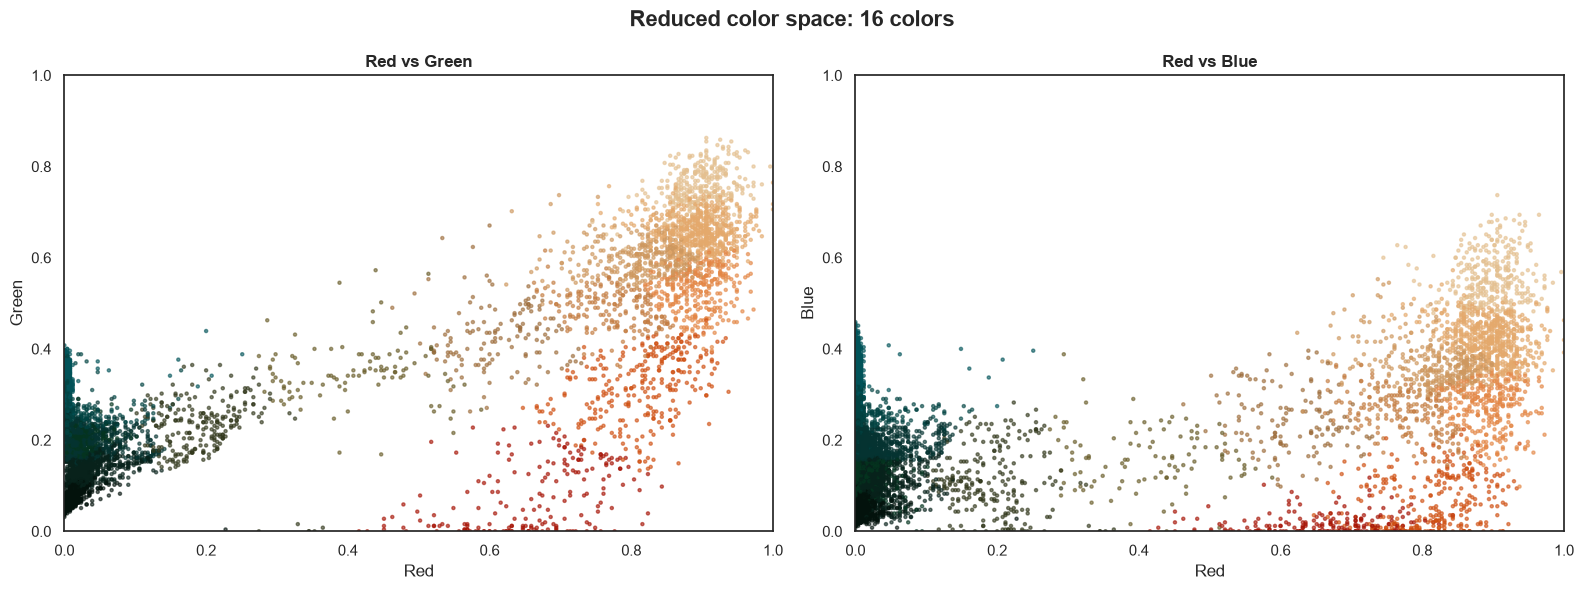

In [7]:
# Visualize the reduced color space
plot_pixels(data, colors=new_colors, title="Reduced color space: 16 colors")


Notice how the continuous cloud of points has collapsed into exactly $16$ discrete color points representing the cluster centroids!


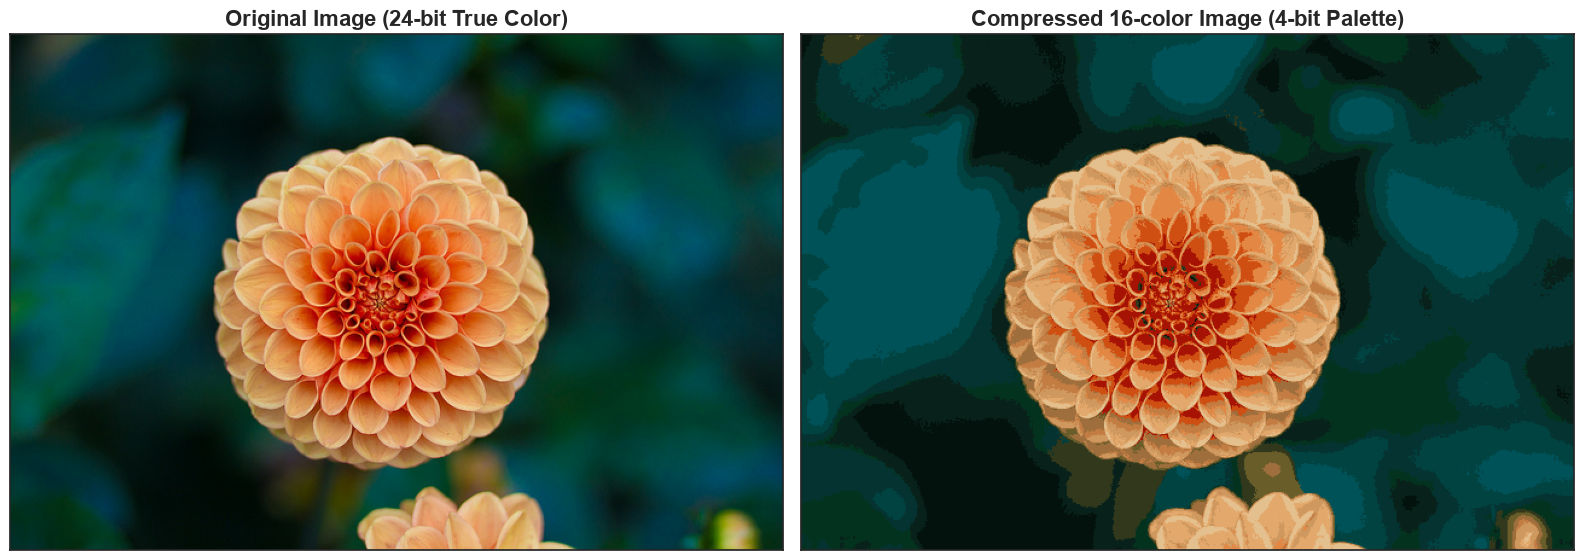

In [8]:
# Reshape the recolored data back into original 3D image shape
flower_recolored = new_colors.reshape(flower.shape)

# Display comparative side-by-side result
fig, ax = plt.subplots(1, 2, figsize=(16, 7),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)

ax[0].imshow(flower)
ax[0].set_title('Original Image (24-bit True Color)', size=16, fontweight='bold')

ax[1].imshow(flower_recolored)
ax[1].set_title('Compressed 16-color Image (4-bit Palette)', size=16, fontweight='bold')

plt.tight_layout()
plt.show()


## Step 5 - Quantitative Image Compression Analysis
Let us quantify the theoretical memory and storage reduction achieved by clustering:

1. **Original Uncompressed Representation (24-bit True Color):**
   - Each pixel stores 3 channels (RGB) $\times$ 8 bits = 24 bits = 3 bytes.
   - For an image of size $427 \times 640 = 273,280$ pixels:
     $$\text{Original Size} = 273,280 \times 3 \text{ bytes} = 819,840 \text{ bytes} \approx 800.63 \text{ KB}$$

2. **Compressed Palettized Representation (16 Colors):**
   - A palette of 16 colors requires:
     $$16 \text{ colors} \times 3 \text{ bytes (RGB)} = 48 \text{ bytes}$$
   - Since $16 = 2^4$, each pixel requires only **4 bits** ($\frac{1}{2}$ byte) to store an index into the palette:
     $$\text{Index Map Size} = 273,280 \times 0.5 \text{ bytes} = 136,640 \text{ bytes}$$
   - Total compressed size:
     $$\text{Total Compressed Size} = 136,640 + 48 = 136,688 \text{ bytes} \approx 133.48 \text{ KB}$$

3. **Compression Ratio & Storage Savings:**
   $$\text{Compression Ratio} = \frac{819,840}{136,688} \approx 5.998 \approx 6\times$$
   $$\text{Storage Savings} = \left(1 - \frac{136,688}{819,840}\right) \times 100\% \approx 83.33\%$$


In [9]:
# Summary table of compression metrics
import pandas as pd
orig_bytes = flower.shape[0] * flower.shape[1] * 3
comp_bytes = int(flower.shape[0] * flower.shape[1] * (np.log2(16) / 8)) + (16 * 3)

comp_df = pd.DataFrame({
    'Metric': ['Image Resolution', 'Color Space', 'Bits Per Pixel (bpp)', 'Raw Data Size', 'Compression Ratio', 'Storage Reduction'],
    'Original Image': [f"{flower.shape[0]}x{flower.shape[1]}", "16,777,216 colors", "24 bits", f"{orig_bytes:,} bytes ({orig_bytes/1024:.2f} KB)", "1.00x", "0.0%"],
    'Compressed Image (K=16)': [f"{flower.shape[0]}x{flower.shape[1]}", "16 colors", "4 bits + palette", f"{comp_bytes:,} bytes ({comp_bytes/1024:.2f} KB)", f"{orig_bytes/comp_bytes:.2f}x", f"{(1 - comp_bytes/orig_bytes)*100:.2f}%"]
})

display(comp_df)


,Metric,Original Image,Compressed Image (K=16)
0,Image Resolution,427x640,427x640
1,Color Space,"16,777,216 colors",16 colors
2,Bits Per Pixel (bpp),24 bits,4 bits + palette
3,Raw Data Size,"819,840 bytes (800.62 KB)","136,688 bytes (133.48 KB)"
4,Compression Ratio,1.00x,6.00x
5,Storage Reduction,0.0%,83.33%


## Step 6 - Visual Quality vs Cluster Count ($K = 4, 8, 16, 32, 64$)
To understand the trade-off between color fidelity and compression degree, we examine results across various values of $K$.


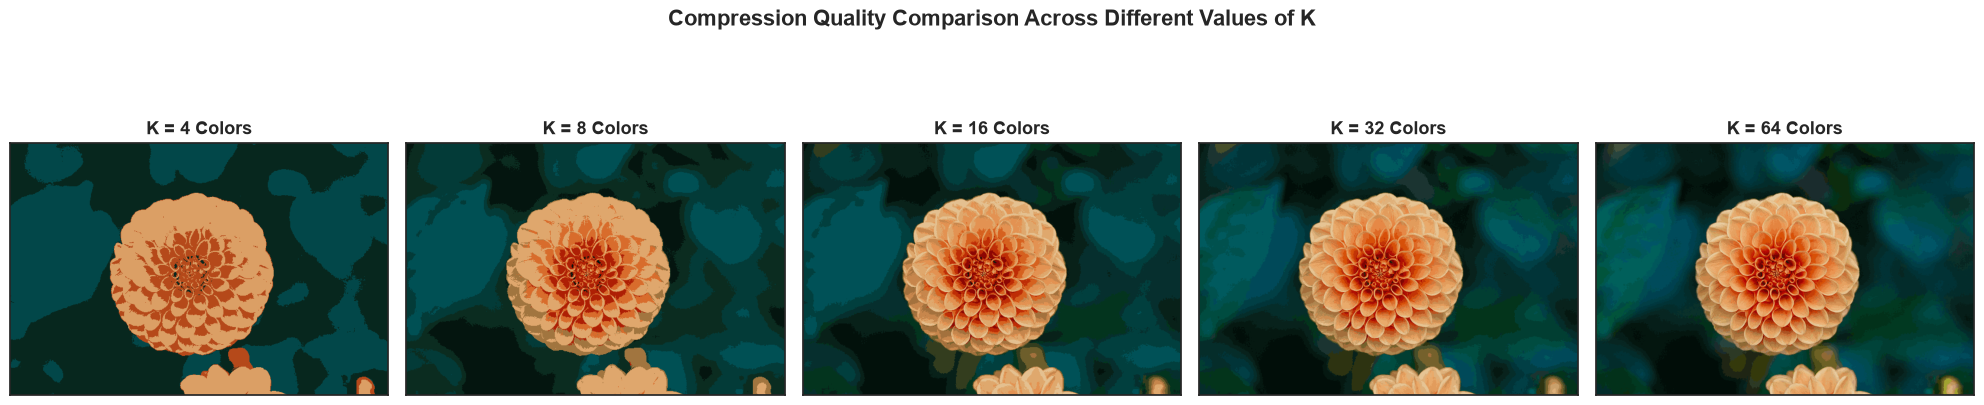

In [10]:
k_values = [4, 8, 16, 32, 64]
fig, axes = plt.subplots(1, len(k_values), figsize=(20, 5), subplot_kw=dict(xticks=[], yticks=[]))

for idx, k in enumerate(k_values):
    km = MiniBatchKMeans(n_clusters=k, random_state=42, batch_size=1024, n_init=5)
    km.fit(data)
    quantized_pixels = km.cluster_centers_[km.predict(data)]
    img_k = quantized_pixels.reshape(flower.shape)
    
    axes[idx].imshow(img_k)
    axes[idx].set_title(f"K = {k} Colors", fontsize=13, fontweight='bold')

plt.suptitle("Compression Quality Comparison Across Different Values of K", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


### Key Takeaways
1. **$K = 4$:** Strong posterization and color banding; prominent loss of subtle gradations, but main contours remain identifiable.
2. **$K = 8$ and $K = 16$:** Excellent compromise; preserves the vibrant red petals and green background while achieving $\approx 83\%$ memory savings.
3. **$K = 32$ and $K = 64$:** Perceptually almost indistinguishable from the 24-bit original image to the human eye, providing near-lossless subjective fidelity at $\approx 75\%$ to $\approx 66\%$ memory reduction.
4. **Vector Quantization Principle:** K-Means identifies optimal Voronoi partitions in 3D color space, demonstrating the broad utility of unsupervised clustering beyond tabular data to multimedia signal compression.
